# Exercício 1 - GAN para representar um paraboloide

A ideia aqui é manter o código mais linear, mostrando o passo a passo do experimento. A GAN continua sendo treinada apenas com o conjunto de pontos `D` em `R³`, sem usar pares supervisionados `z -> S(z)` no treino.

### Importação de Bibliotecas

In [46]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset

### Paraboloide e dataset

A superfície é dada por:

`S(x1, x2) = (x1, x2, x1² + x2² + 1)`

In [47]:
def S(x):
    x1 = x[:, 0]
    x2 = x[:, 1]
    z = x1**2 + x2**2 + 1
    return torch.stack([x1, x2, z], dim=1)

In [48]:
# Número de pontos usados no dataset
N = 5000

# Pontos no domínio [-2, 2] x [-2, 2]
X = -2 + 4 * torch.rand(N, 2)

# Pontos reais no paraboloide em R³
D = S(X)

print("Shape de X:", X.shape)
print("Shape de D:", D.shape)

Shape de X: torch.Size([5000, 2])
Shape de D: torch.Size([5000, 3])


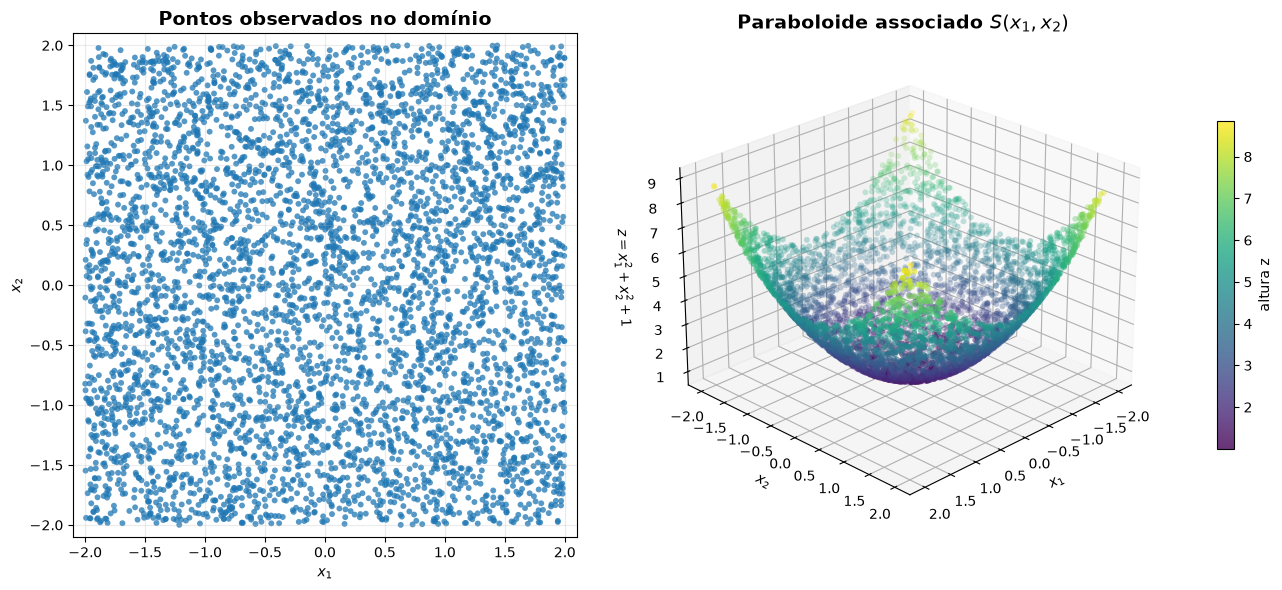

In [49]:
fig = plt.figure(figsize=(14, 6))

# Domínio observado
ax1 = fig.add_subplot(1, 2, 1)

ax1.scatter(
    X[:, 0],
    X[:, 1],
    s=18,
    alpha=0.75,
    edgecolors="none"
)

ax1.set_title("Pontos observados no domínio", fontsize=14, weight="bold")
ax1.set_xlabel(r"$x_1$")
ax1.set_ylabel(r"$x_2$")
ax1.set_xlim(-2.1, 2.1)
ax1.set_ylim(-2.1, 2.1)
ax1.set_aspect("equal")
ax1.grid(True, alpha=0.25)

# Paraboloide associado
ax2 = fig.add_subplot(1, 2, 2, projection="3d")

sc = ax2.scatter(
    D[:, 0],
    D[:, 1],
    D[:, 2],
    c=D[:, 2],
    s=18,
    alpha=0.8,
    edgecolors="none"
)

ax2.set_title(r"Paraboloide associado $S(x_1,x_2)$", fontsize=14, weight="bold")
ax2.set_xlabel(r"$x_1$")
ax2.set_ylabel(r"$x_2$")
ax2.set_zlabel(r"$z = x_1^2 + x_2^2 + 1$")

ax2.view_init(elev=25, azim=45)
ax2.grid(True, alpha=0.25)

fig.colorbar(sc, ax=ax2, shrink=0.65, pad=0.1, label="altura z")

plt.tight_layout()
plt.show()

### Separação treino/teste e normalização

A normalização ajuda porque as coordenadas têm escalas diferentes: `x1` e `x2` ficam em `[-2, 2]`, enquanto a coordenada `z` fica aproximadamente entre `1` e `9`.

In [50]:
# Embaralha os índices e separa 80% treino / 20% teste
perm = torch.randperm(N)
train_size = int(0.8 * N)
train_idx = perm[:train_size]
test_idx = perm[train_size:]

D_train = D[train_idx]
D_test = D[test_idx]

# Normalização z-score
D_mean = D_train.mean(dim=0)
D_std = D_train.std(dim=0)

D_train_norm = (D_train - D_mean) / D_std

dataset = TensorDataset(D_train_norm)
loader = DataLoader(dataset, batch_size=128, shuffle=True, drop_last=True)

print("Shape de D_train:", D_train.shape)
print("Shape de D_test:", D_test.shape)

Shape de D_train: torch.Size([4000, 3])
Shape de D_test: torch.Size([1000, 3])


### Definição de Arquitetura da Rede Geradora e Discriminadora

O modelo abaixo implementa uma GAN convencional. O discriminador usa `Sigmoid` na saída e produz uma probabilidade entre 0 e 1.

In [51]:
class Generator(nn.Module):
    def __init__(self, latent_dim=2, hidden_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, 3),
        )

    def forward(self, z):
        return self.net(z)


class Discriminator(nn.Module):
    def __init__(self, input_dim=3, hidden_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, 1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        return self.net(x)

In [52]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

latent_dim = 2
G = Generator(latent_dim=latent_dim).to(device)
D = Discriminator(input_dim=3).to(device)

opt_G = torch.optim.Adam(G.parameters(), lr=1e-4, betas=(0.9, 0.999))
opt_D = torch.optim.Adam(D.parameters(), lr=1e-4, betas=(0.9, 0.999))

print("Device:", device)
print(G)
print(D)

Device: cpu
Generator(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=128, bias=True)
    (1): SiLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): SiLU()
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): SiLU()
    (6): Linear(in_features=128, out_features=3, bias=True)
  )
)
Discriminator(
  (net): Sequential(
    (0): Linear(in_features=3, out_features=128, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): LeakyReLU(negative_slope=0.2)
    (6): Linear(in_features=128, out_features=1, bias=True)
    (7): Sigmoid()
  )
)


## (a). Treinamento adversarial

Aqui o treino fica explícito no notebook, atualizando o discriminador `k` vezes para cada vez que o gerador é atualizado.

A perda do discriminador é:

`-E[log(D(real))] - E[log(1 - D(fake))]`

A perda do gerador é:

`-E[log(D(fake))]`

In [53]:
epochs = 300
z_min, z_max = -2.0, 2.0
k = 1  # atualiza o discriminador k vezes para cada vez do gerador

criterion = nn.BCELoss()

history_D = []
history_G = []

for epoch in range(epochs):
    total_loss_D = 0.0
    total_loss_G = 0.0

    for batch in loader:
        real_points = batch[0].to(device)
        batch_size = real_points.shape[0]

        # 1) Atualiza o discriminador k vezes
        for _ in range(k):
            z = z_min + (z_max - z_min) * torch.rand(batch_size, latent_dim, device=device)
            fake_points = G(z).detach()

            real_labels = torch.ones(batch_size, 1, device=device)
            fake_labels = torch.zeros(batch_size, 1, device=device)

            real_loss = criterion(D(real_points), real_labels)
            fake_loss = criterion(D(fake_points), fake_labels)
            loss_D = real_loss + fake_loss

            opt_D.zero_grad()
            loss_D.backward()
            opt_D.step()

        # 2) Atualiza o gerador uma vez
        z = z_min + (z_max - z_min) * torch.rand(batch_size, latent_dim, device=device)
        fake_points = G(z)
        loss_G = criterion(D(fake_points), real_labels)

        opt_G.zero_grad()
        loss_G.backward()
        opt_G.step()

        total_loss_D += loss_D.item()
        total_loss_G += loss_G.item()

    mean_loss_D = total_loss_D / len(loader)
    mean_loss_G = total_loss_G / len(loader)

    history_D.append(mean_loss_D)
    history_G.append(mean_loss_G)

    if (epoch + 1) % 20 == 0:
        print(
            f"Epoch [{epoch + 1}/{epochs}] | "
            f"Loss D: {mean_loss_D:.4f} | "
            f"Loss G: {mean_loss_G:.4f}"
        )

Epoch [20/300] | Loss D: 1.3136 | Loss G: 0.7395
Epoch [40/300] | Loss D: 1.2283 | Loss G: 0.8349
Epoch [60/300] | Loss D: 1.3144 | Loss G: 0.7702
Epoch [80/300] | Loss D: 1.2458 | Loss G: 0.8302
Epoch [100/300] | Loss D: 1.3794 | Loss G: 0.7037
Epoch [120/300] | Loss D: 1.3783 | Loss G: 0.7109
Epoch [140/300] | Loss D: 1.3898 | Loss G: 0.7109
Epoch [160/300] | Loss D: 1.3871 | Loss G: 0.6985
Epoch [180/300] | Loss D: 1.3865 | Loss G: 0.7011
Epoch [200/300] | Loss D: 1.3838 | Loss G: 0.7075
Epoch [220/300] | Loss D: 1.3885 | Loss G: 0.6945
Epoch [240/300] | Loss D: 1.3889 | Loss G: 0.6974
Epoch [260/300] | Loss D: 1.3898 | Loss G: 0.7155
Epoch [280/300] | Loss D: 1.3883 | Loss G: 0.6958
Epoch [300/300] | Loss D: 1.3847 | Loss G: 0.7155


### Curvas de treinamento

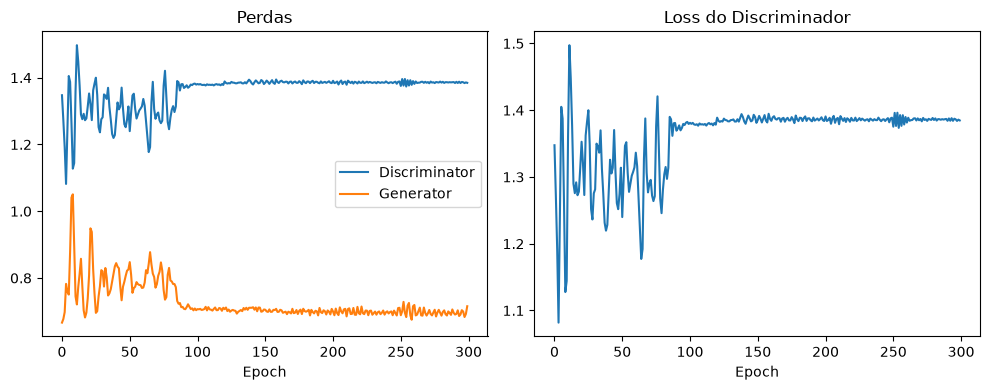

In [54]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].plot(history_D, label="Discriminator")
ax[0].plot(history_G, label="Generator")
ax[0].set_title("Perdas")
ax[0].set_xlabel("Epoch")
ax[0].legend()

ax[1].plot(history_D)
ax[1].set_title("Loss do Discriminador")
ax[1].set_xlabel("Epoch")

plt.tight_layout()
plt.show()

### Observando o paraboloide gerado pelo S(x) e comparando com G

Paraboloide real (esquerda) versus gerado pela GAN (direita), usando os mesmos `z` na entrada.

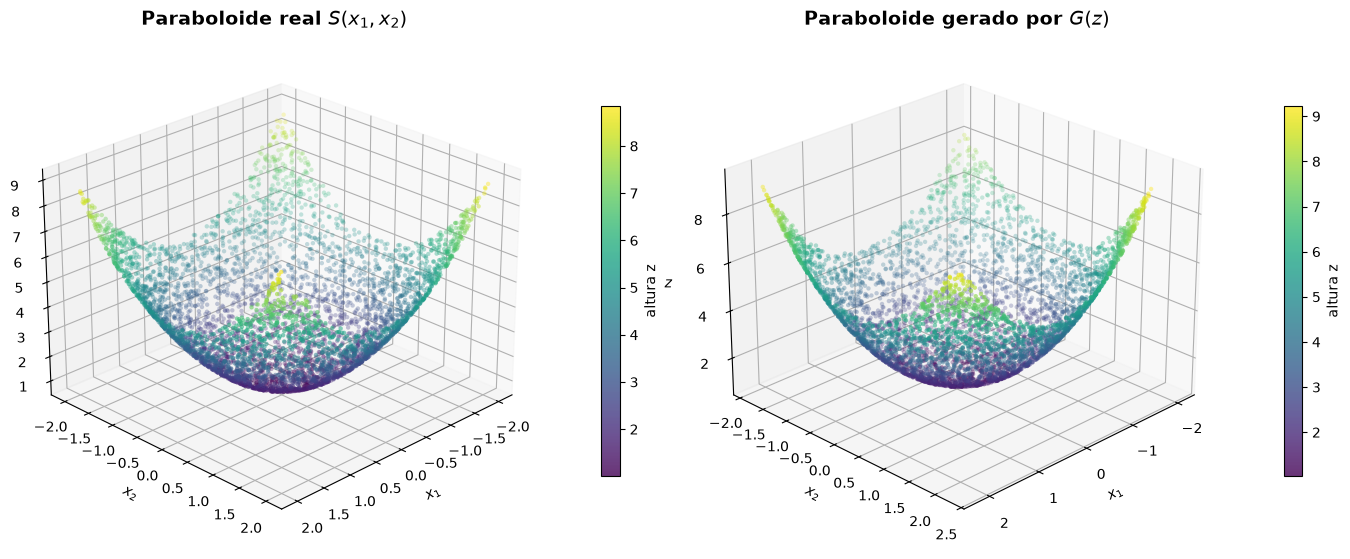

In [55]:
G.eval()

N_vis = 5000
Z_vis = z_min + (z_max - z_min) * torch.rand(N_vis, latent_dim, device=device)

with torch.no_grad():
    Y_vis_norm = G(Z_vis)
    Y_vis = Y_vis_norm * D_std.to(device) + D_mean.to(device)

Y_true = S(Z_vis).to(device)

Y_vis = Y_vis.cpu()
Y_true = Y_true.cpu()

fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(1, 2, 1, projection="3d")
sc1 = ax1.scatter(Y_true[:, 0], Y_true[:, 1], Y_true[:, 2],
                  c=Y_true[:, 2], s=10, alpha=0.8, edgecolors="none")
ax1.set_title(r"Paraboloide real $S(x_1,x_2)$", fontsize=14, weight="bold")
ax1.set_xlabel(r"$x_1$"); ax1.set_ylabel(r"$x_2$"); ax1.set_zlabel(r"$z$")
ax1.view_init(elev=25, azim=45); ax1.grid(True, alpha=0.25)
fig.colorbar(sc1, ax=ax1, shrink=0.65, pad=0.1, label="altura z")

ax2 = fig.add_subplot(1, 2, 2, projection="3d")
sc2 = ax2.scatter(Y_vis[:, 0], Y_vis[:, 1], Y_vis[:, 2],
                  c=Y_vis[:, 2], s=10, alpha=0.8, edgecolors="none")
ax2.set_title(r"Paraboloide gerado por $G(z)$", fontsize=14, weight="bold")
ax2.set_xlabel(r"$x_1$"); ax2.set_ylabel(r"$x_2$"); ax2.set_zlabel(r"$z$")
ax2.view_init(elev=25, azim=45); ax2.grid(True, alpha=0.25)
fig.colorbar(sc2, ax=ax2, shrink=0.65, pad=0.1, label="altura z")

plt.tight_layout()
plt.show()

## (b) Avaliação do gerador

A comparação `G(z)` versus `S(z)` mede se o gerador aprendeu a mesma parametrização. Já o erro geométrico mede se os pontos gerados pertencem ao paraboloide, independentemente da parametrização.

In [56]:
G.eval()

N_test = 5000
Z = z_min + (z_max - z_min) * torch.rand(N_test, latent_dim, device=device)

with torch.no_grad():
    Y_true = S(Z).to(device)

    # O gerador produz pontos normalizados. Aqui voltamos para a escala original.
    Y_pred_norm = G(Z)
    Y_pred = Y_pred_norm * D_std.to(device) + D_mean.to(device)

error = Y_pred - Y_true

mae = torch.mean(torch.abs(error))
rmse = torch.sqrt(torch.mean(error**2))
mae_per_coord = torch.mean(torch.abs(error), dim=0)
rmse_per_coord = torch.sqrt(torch.mean(error**2, dim=0))

surface_error = Y_pred[:, 2] - Y_pred[:, 0]**2 - Y_pred[:, 1]**2 - 1
surface_mae = torch.mean(torch.abs(surface_error))
surface_rmse = torch.sqrt(torch.mean(surface_error**2))

print("MAE ponto a ponto:", mae.item())
print("RMSE ponto a ponto:", rmse.item())
print("MAE por coordenada [x1, x2, z]:", mae_per_coord.cpu().numpy())
print("RMSE por coordenada [x1, x2, z]:", rmse_per_coord.cpu().numpy())
print("MAE geométrico da superfície:", surface_mae.item())
print("RMSE geométrico da superfície:", surface_rmse.item())

# Erros relativos
mae_rel = mae / torch.mean(torch.abs(Y_true))
rmse_rel = rmse / torch.sqrt(torch.mean(Y_true ** 2))
mae_rel_per_coord = mae_per_coord / torch.mean(torch.abs(Y_true), dim=0)
rmse_rel_per_coord = rmse_per_coord / torch.std(Y_true, dim=0)

print("MAE relativo (%):", round(mae_rel.item() * 100, 2))
print("RMSE relativo (%):", round(rmse_rel.item() * 100, 2))
print("MAE relativo por coord [x1, x2, z] (%):", [round(v * 100, 2) for v in mae_rel_per_coord.cpu().numpy()])
print("RMSE relativo por coord [x1, x2, z] (%):", [round(v * 100, 2) for v in rmse_rel_per_coord.cpu().numpy()])

MAE ponto a ponto: 0.8108301162719727
RMSE ponto a ponto: 1.371781349182129
MAE por coordenada [x1, x2, z]: [0.11973965 2.029789   0.2829615 ]
RMSE por coordenada [x1, x2, z]: [0.13954255 2.3433783  0.36668614]
MAE geométrico da superfície: 0.18358799815177917
RMSE geométrico da superfície: 0.25516992807388306
MAE relativo (%): 43.13
RMSE relativo (%): 54.95
MAE relativo por coord [x1, x2, z] (%): [np.float32(11.99), np.float32(204.37), np.float32(7.76)]
RMSE relativo por coord [x1, x2, z] (%): [np.float32(12.11), np.float32(204.01), np.float32(22.14)]


### Visualização do espaço latente e das coordenadas geradas

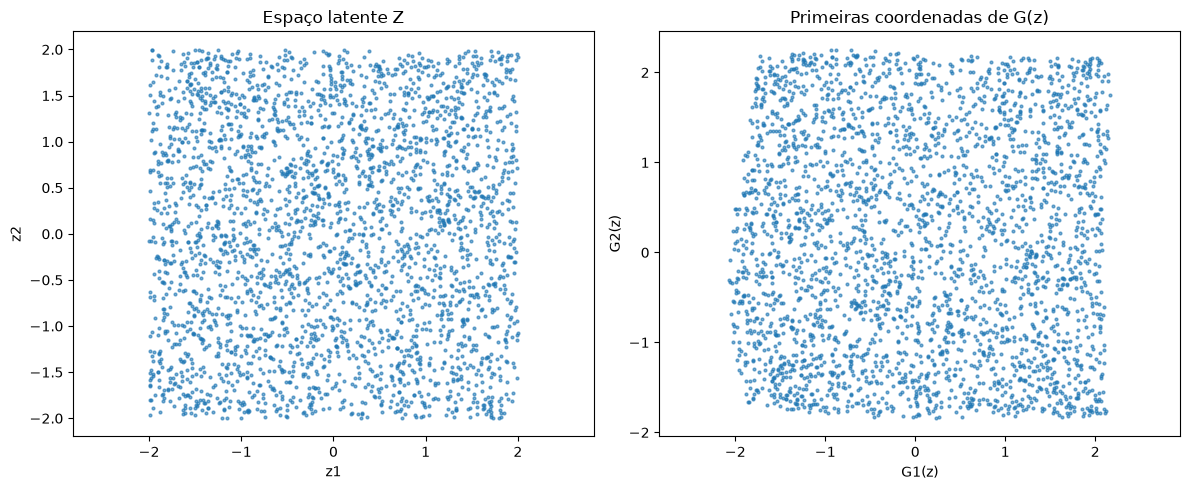

In [57]:
N_vis = 3000
Z_vis = z_min + (z_max - z_min) * torch.rand(N_vis, latent_dim, device=device)

with torch.no_grad():
    Y_vis_norm = G(Z_vis)
    Y_vis = Y_vis_norm * D_std.to(device) + D_mean.to(device)

Z_vis = Z_vis.cpu()
Y_vis = Y_vis.cpu()

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].scatter(Z_vis[:, 0], Z_vis[:, 1], s=4, alpha=0.6)
ax[0].set_title("Espaço latente Z")
ax[0].set_xlabel("z1")
ax[0].set_ylabel("z2")
ax[0].axis("equal")

ax[1].scatter(Y_vis[:, 0], Y_vis[:, 1], s=4, alpha=0.6)
ax[1].set_title("Primeiras coordenadas de G(z)")
ax[1].set_xlabel("G1(z)")
ax[1].set_ylabel("G2(z)")
ax[1].axis("equal")

plt.tight_layout()
plt.show()

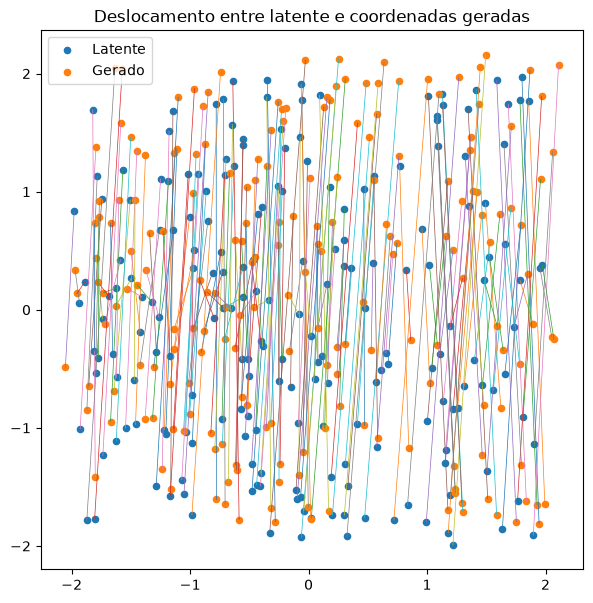

In [58]:
N_lines = 200
Z_lines = z_min + (z_max - z_min) * torch.rand(N_lines, latent_dim, device=device)

with torch.no_grad():
    Y_lines_norm = G(Z_lines)
    Y_lines = Y_lines_norm * D_std.to(device) + D_mean.to(device)

Z_lines = Z_lines.cpu()
Y_lines = Y_lines.cpu()

plt.figure(figsize=(7, 7))
plt.scatter(Z_lines[:, 0], Z_lines[:, 1], s=20, label="Latente")
plt.scatter(Y_lines[:, 0], Y_lines[:, 1], s=20, label="Gerado")

for i in range(N_lines):
    plt.plot(
        [Z_lines[i, 0], Y_lines[i, 0]],
        [Z_lines[i, 1], Y_lines[i, 1]],
        linewidth=0.5,
    )

plt.axis("equal")
plt.legend()
plt.title("Deslocamento entre latente e coordenadas geradas")
plt.show()

In [59]:
# N_lines = 200
# Z_lines = z_min + (z_max - z_min) * torch.rand(N_lines, latent_dim, device=device)

# with torch.no_grad():
#     Y_lines_norm = G(Z_lines)
#     Y_lines = Y_lines_norm * D_std.to(device) + D_mean.to(device)

# Z_lines = Z_lines.cpu()
# Z_lines = -Z_lines
# Y_lines = Y_lines.cpu()

# plt.figure(figsize=(7, 7))
# plt.scatter(Z_lines[:, 0], Z_lines[:, 1], s=20, label="Latente")
# plt.scatter(Y_lines[:, 0], Y_lines[:, 1], s=20, label="Gerado")

# for i in range(N_lines):
#     plt.plot(
#         [Z_lines[i, 0], Y_lines[i, 0]],
#         [Z_lines[i, 1], Y_lines[i, 1]],
#         linewidth=0.5,
#     )

# plt.axis("equal")
# plt.legend()
# plt.title("Deslocamento entre latente e coordenadas geradas")
# plt.show()

## (c) Comparação entre ∇G (autograd) e ∇S (analítico)

Calcula-se o Jacobiano do gerador `G` via diferenciação automática sobre um conjunto de pontos `Z` no espaço latente, e compara-se com o Jacobiano analítico da superfície `S(x₁, x₂) = (x₁, x₂, x₁² + x₂² + 1)`.

In [60]:
G.eval()

N_grad = 200
Z_grad = z_min + (z_max - z_min) * torch.rand(N_grad, latent_dim, device=device)

# --- Jacobiano analítico de S: R² -> R³ ---
def jacobian_S(Z):
    B = Z.shape[0]
    J = torch.zeros(B, 3, 2, device=Z.device)
    J[:, 0, 0] = 1.0          # ∂x1/∂z1
    J[:, 1, 1] = 1.0          # ∂x2/∂z2
    J[:, 2, 0] = 2 * Z[:, 0]  # ∂z/∂z1 = 2*z1
    J[:, 2, 1] = 2 * Z[:, 1]  # ∂z/∂z2 = 2*z2
    return J

J_S = jacobian_S(Z_grad)

# --- Jacobiano de G via autograd ---
J_G = torch.zeros_like(J_S)
for i in range(N_grad):
    z_i = Z_grad[i:i+1].requires_grad_(True)
    g_i = G(z_i)
    for d in range(3):
        grads = torch.autograd.grad(g_i[0, d], z_i, retain_graph=True)[0]
        J_G[i, d] = grads[0]

# --- Comparação ---
diff = J_G - J_S
frobenius_per_point = torch.norm(diff.view(N_grad, -1), dim=1)

print("Norma de Frobenius média de (∇G - ∇S):", frobenius_per_point.mean().item())
print("Desvio padrão:", frobenius_per_point.std().item())
print()

# Comparação componente a componente
out_names = ["x1", "x2", "z"]
in_names = ["z1", "z2"]
print(f"{'':>8}", "".join(f"{'∂' + o + '/' + i:>14}" for o in out_names for i in in_names))
print(f"{'∇G':>8}", "".join(f"{J_G[:, d_out, d_in].mean().item():>14.4f}"
      for d_out in range(3) for d_in in range(2)))
print(f"{'∇S':>8}", "".join(f"{J_S[:, d_out, d_in].mean().item():>14.4f}"
      for d_out in range(3) for d_in in range(2)))
print(f"{'∇G-∇S':>8}", "".join(f"{diff[:, d_out, d_in].mean().item():>14.4f}"
      for d_out in range(3) for d_in in range(2)))

Norma de Frobenius média de (∇G - ∇S): 2.2839267253875732
Desvio padrão: 0.2966616451740265

                 ∂x1/z1        ∂x1/z2        ∂x2/z1        ∂x2/z2         ∂z/z1         ∂z/z2
      ∇G         0.8618       -0.0403       -0.0491       -0.8681       -0.1135       -0.1907
      ∇S         1.0000        0.0000        0.0000        1.0000       -0.2228       -0.1489
   ∇G-∇S        -0.1382       -0.0403       -0.0491       -1.8681        0.1093       -0.0418
